# LpWM: a world model with sparse latents

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/latent-horizon/pytorch-world/blob/main/examples/action/lpwm.ipynb)

[LpWM](https://arxiv.org/abs/2608.22764) ([code](https://github.com/YilunKuang/lpworldmodel)) is LeWM with sparse, non-negative latents. A ReLU link zeroes most units, and RDMReg, which matches the latents to a rectified Laplace, sets how many and keeps them from collapsing. The paper finds that *which* units fire encodes discrete facts and *how strongly* they fire encodes continuous ones.

Here a macaw learns to fly a sky split by a rock wall with one gap, where the discrete fact is the side of the wall, then plans toward goal images.

In [ ]:
import importlib.util

if importlib.util.find_spec("torch_world") is None:  # on Colab
    %pip install -q "torch-world[examples]"

In [2]:
import torch
from torch.utils.data import DataLoader

from torch_world import evaluation, metrics, plots
from torch_world.datasets import TrajectoryDataset
from torch_world.envs import Macaw
from torch_world.models import LpWM
from torch_world.nn import CLSEncoder
from torch_world.planning import CEM
from torch_world.utils import fit

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"

## Data and model
The macaw flies at random through a sky split by a rock wall with one gap. As in the paper's two-room task, the model sees one frame of history. The loss is next-latent prediction plus 10 × RDMReg.

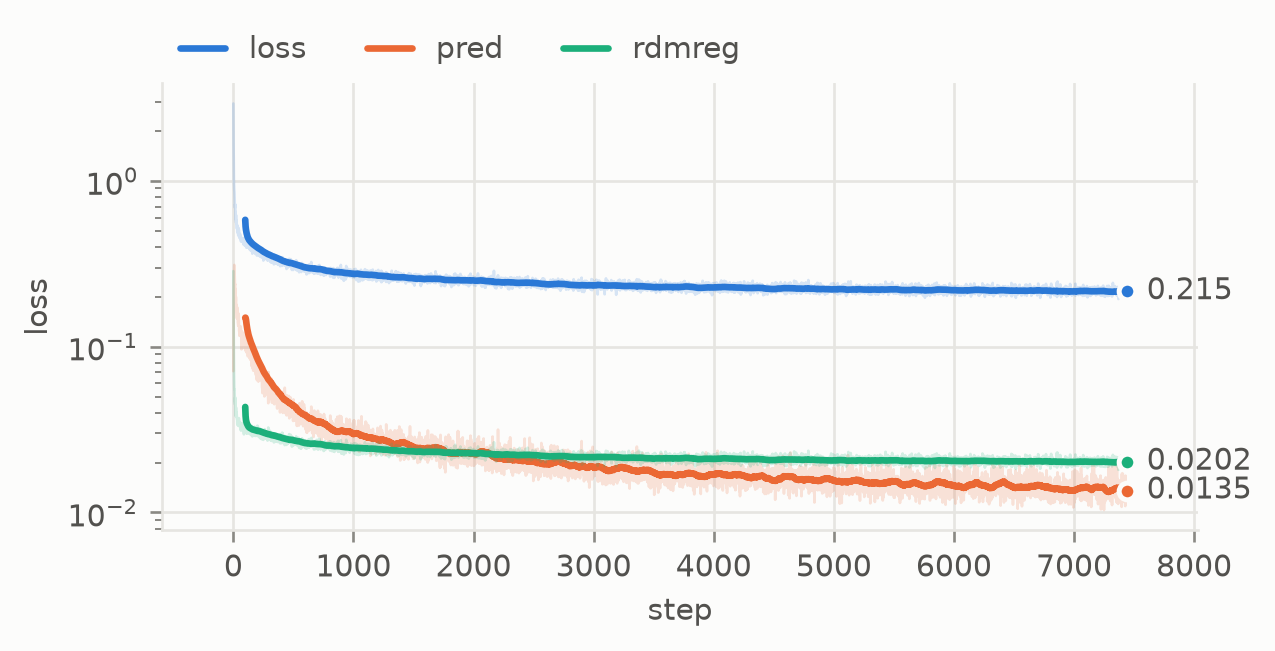

In [3]:
data = Macaw(batch_size=1024, rooms=True, device=device).collect(32, generator=torch.Generator().manual_seed(0))
loader = DataLoader(TrajectoryDataset(data, window=2), batch_size=128, shuffle=True, drop_last=True)

encoder = CLSEncoder(img_size=64, patch_size=8, depth=6, num_heads=3)
model = LpWM(encoder, action_dim=2, history=1, depth=6, num_heads=8, head_dim=32, mlp_dim=768, proj_dim=768).to(device)
log = fit(model, loader, epochs=30, lr=3e-4, clip=1.0)
plots.curves(log, smooth=100)

## What the sparse latents say
Encode the macaw at every free cell of a 40 × 40 grid. A linear probe reads the side of the wall from *which* units are on, and the position from their values.

In [4]:
env = Macaw(rooms=True)
axis = torch.linspace(env.low, env.high, 40)
grid = torch.stack(torch.meshgrid(axis, axis, indexing="xy"), -1).flatten(0, 1)
grid = grid[~env.blocked(grid)]
with torch.no_grad():
    z = model.encode(env.render(grid)[:, None].to(device))[:, 0].cpu()
on, room = (z > 0).float(), env.room(grid)

train, test = torch.randperm(len(z), generator=torch.Generator().manual_seed(0)).chunk(2)
print(f"active units per frame: {on.mean():.0%}")
print(f"side of the wall from which units fire: accuracy {metrics.linear_probe(on[train], room[train], on[test], room[test]).score:.1%}")
print(f"position from the values: R² {metrics.linear_probe(z[train], grid[train], z[test], grid[test]).score:.3f}")

active units per frame: 37%
side of the wall from which units fire: accuracy 99.7%
position from the values: R² 0.995


## Plan toward goal images
CEM searches 5-step plans in latent space toward the goal image's latent, and runs the first action of each. The goals are on the other side of the wall, so the way there is through the gap.

In [5]:
env = Macaw(batch_size=32, rooms=True, device=device)
start, goal = env.tasks(generator=torch.Generator().manual_seed(1))  # start and goal on opposite sides of the wall
goal_images = env.render(goal)

planner = CEM(horizon=5, action_dim=2, num_samples=300, num_elites=30, bounds=(-1, 1), objective="path")
policies = {"LpWM + CEM": evaluation.goal_policy(model, planner, goal_images), "random actions": evaluation.random_policy(env)}
result = evaluation.goal_reaching(env, policies, start, goal, steps=40, success="reached")
result

                          success  reached   steps  final distance  progress     SPL  smoothness  ms / step
LpWM + CEM         38% [23%, 55%]      38%    3.58           0.436     0.246    0.23       0.498    7.4e+03
random actions       9% [3%, 24%]       9%      16           0.524    0.0011  0.0123        1.03      0.109

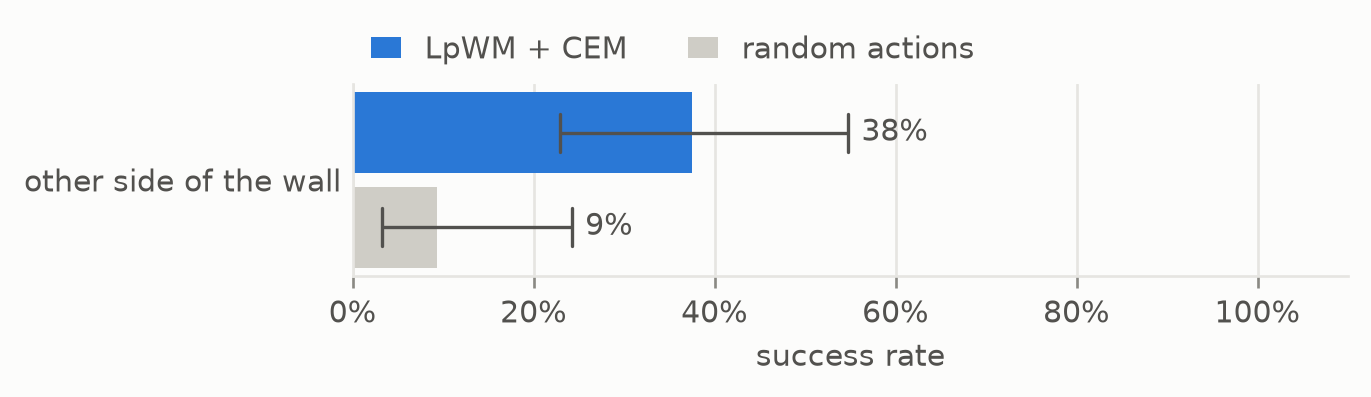

In [6]:
plots.bars({"other side of the wall": result.intervals()}, xlabel="success rate", baseline="random actions")

## Summary
LpWM changes two things in LeWM: a ReLU link, so latents are non-negative with exact zeros, and RDMReg in place of SIGReg. The probes test the paper's reading of sparse latents: the set of active units carries the side of the wall, their values the position. Planning uses the latents as they are, with the same CEM as any world model.